## Q1. Load the file. Report shape, dtypes, and missing counts.

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

loan_file = glob.glob("*suvidha_loan_predictions_raw*.csv")[0]
df = pd.read_csv(loan_file)
print("Shape:", df.shape)
print(df.dtypes)
print("Missing counts:")
print(df.isna().sum())

Shape: (2400, 9)
loan_id            object
loan_amount        object
tenure_months       int64
interest_rate     float64
borrower_age       object
monthly_income     object
actual_default     object
model_flag         object
risk_score        float64
dtype: object
Missing counts:
loan_id            0
loan_amount        0
tenure_months      0
interest_rate      0
borrower_age      38
monthly_income    36
actual_default    40
model_flag        22
risk_score         0
dtype: int64


## Q2. Clean loan_amount to numeric.

In [2]:
df["loan_amount"] = pd.to_numeric(
    df["loan_amount"].astype(str)
    .str.replace(r"^\s*Rs\s*", "", regex=True)
    .str.replace(",", "", regex=False),
    errors="coerce"
)
print("loan_amount dtype:", df["loan_amount"].dtype)
print("Missing loan_amount:", df["loan_amount"].isna().sum())
print(df["loan_amount"].describe())

loan_amount dtype: float64
Missing loan_amount: 0
count      2400.000000
mean      92862.462195
std       39819.158429
min       22062.878150
25%       63410.589692
50%       86127.625580
75%      114590.619250
max      287236.577800
Name: loan_amount, dtype: float64


## Q3. Standardize actual_default and model_flag to boolean and show raw values mapped.

In [3]:
boolean_mapping = {"yes": True, "y": True, "1": True, "true": True, "no": False, "n": False, "0": False, "false": False}
actual_raw_values = sorted(df["actual_default"].dropna().astype(str).str.strip().unique())
model_raw_values = sorted(df["model_flag"].dropna().astype(str).str.strip().unique())
df["actual_default"] = df["actual_default"].astype(str).str.strip().str.lower().map(boolean_mapping)
df["model_flag"] = df["model_flag"].astype(str).str.strip().str.lower().map(boolean_mapping)
print("Raw actual_default values:", actual_raw_values)
print("Raw model_flag values:", model_raw_values)
print("Mapped actual_default:")
print(df["actual_default"].value_counts(dropna=False))
print("Mapped model_flag:")
print(df["model_flag"].value_counts(dropna=False))

Raw actual_default values: ['0', '1', 'FALSE', 'N', 'No', 'TRUE', 'Y', 'Yes']
Raw model_flag values: ['0', '1', 'FALSE', 'N', 'No', 'TRUE', 'Y', 'Yes']
Mapped actual_default:
actual_default
False    2161
True      199
NaN        40
Name: count, dtype: int64
Mapped model_flag:
model_flag
False    2222
True      156
NaN        22
Name: count, dtype: int64


## Q4. Drop rows where actual_default or model_flag is blank and save the cleaned CSV.

In [4]:
before_rows = len(df)
excluded_mask = df["actual_default"].isna() | df["model_flag"].isna()
df = df.loc[~excluded_mask].reset_index(drop=True)
dropped_rows = before_rows - len(df)
df.to_csv("/mnt/data/suvidha_loan_predictions_cleaned.csv", index=False)
print("Rows dropped:", dropped_rows)
print("Final rows:", len(df))
print("Cleaned CSV:", "/mnt/data/suvidha_loan_predictions_cleaned.csv")
print("Reason: blank actual_default means the 90-day outcome is not known, while blank model_flag means no prediction exists; neither value can be validly imputed for classification metrics.")

Rows dropped: 61
Final rows: 2339
Cleaned CSV: /mnt/data/suvidha_loan_predictions_cleaned.csv
Reason: blank actual_default means the 90-day outcome is not known, while blank model_flag means no prediction exists; neither value can be validly imputed for classification metrics.


## Q5. Clean monthly_income and distinguish the missing reasons.

In [5]:
raw_income = df["monthly_income"].astype(str).str.strip()
df["income_missing_reason"] = np.select(
    [raw_income.eq("-1"), raw_income.str.lower().eq("not disclosed")],
    ["invalid sentinel", "not disclosed"],
    default="observed"
)
df["monthly_income"] = pd.to_numeric(
    raw_income.replace({"-1": np.nan, "not disclosed": np.nan}),
    errors="coerce"
)
print(df["income_missing_reason"].value_counts())
print("Missing monthly_income after cleaning:", df["monthly_income"].isna().sum())
print("Decision: both values are excluded from the numeric income field, but the reason is preserved because -1 is an invalid sentinel while 'not disclosed' represents unknown information supplied by the borrower.")

income_missing_reason
observed            2282
not disclosed         29
invalid sentinel      28
Name: count, dtype: int64
Missing monthly_income after cleaning: 91
Decision: both values are excluded from the numeric income field, but the reason is preserved because -1 is an invalid sentinel while 'not disclosed' represents unknown information supplied by the borrower.


## Q6. Build the confusion matrix and label TP, FP, TN, FN in business terms.

In [6]:
actual = df["actual_default"].astype(bool)
predicted = df["model_flag"].astype(bool)
cm = confusion_matrix(actual, predicted, labels=[True, False])
cm_table = pd.DataFrame(cm, index=["Actual default", "Actual no default"], columns=["Predicted default", "Predicted no default"])
display(cm_table)
tp, fn, fp, tn = int(cm[0,0]), int(cm[0,1]), int(cm[1,0]), int(cm[1,1])
print("TP:", tp, "A true defaulter was flagged for early collection.")
print("FP:", fp, "A non-defaulter was flagged unnecessarily.")
print("TN:", tn, "A non-defaulter was correctly left unflagged.")
print("FN:", fn, "A true defaulter was missed by the model.")

,Predicted default,Predicted no default
Actual default,133,64
Actual no default,20,2122


TP: 133 A true defaulter was flagged for early collection.
FP: 20 A non-defaulter was flagged unnecessarily.
TN: 2122 A non-defaulter was correctly left unflagged.
FN: 64 A true defaulter was missed by the model.


## Q7. Compute accuracy and explain why it is misleading with a 9% default rate.

In [7]:
accuracy = accuracy_score(actual, predicted)
default_rate = actual.mean()
print("Accuracy:", accuracy)
print("Observed default rate:", default_rate)
print("Interpretation: accuracy is high partly because non-defaults dominate the sample. A model that predicted no default for everyone would achieve about {:.2%} accuracy, so accuracy alone does not reveal how many true defaults are missed.".format(1 - default_rate))

Accuracy: 0.9640872167592989
Observed default rate: 0.08422402736212056
Interpretation: accuracy is high partly because non-defaults dominate the sample. A model that predicted no default for everyone would achieve about 91.58% accuracy, so accuracy alone does not reveal how many true defaults are missed.


## Q8. Compute precision for predicted default and interpret it for a collections officer.

In [8]:
precision = precision_score(actual, predicted)
print("Precision:", precision)
print(f"Interpretation: when the model flags a borrower as likely to default, about {precision:.2%} of those flagged loans actually defaulted in this pilot.")

Precision: 0.869281045751634
Interpretation: when the model flags a borrower as likely to default, about 86.93% of those flagged loans actually defaulted in this pilot.


## Q9. Compute recall for predicted default and interpret missed defaults.

In [9]:
recall = recall_score(actual, predicted)
print("Recall:", recall)
print(f"Interpretation: the model detected about {recall:.2%} of all observed defaults and missed {fn} of {tp + fn} actual defaults.")

Recall: 0.6751269035532995
Interpretation: the model detected about 67.51% of all observed defaults and missed 64 of 197 actual defaults.


## Q10. Compute specificity and explain the operational cost of low specificity.

In [10]:
specificity = tn / (tn + fp)
print("Specificity:", specificity)
print(f"Interpretation: the model correctly leaves {specificity:.2%} of non-defaulters unflagged. The {fp} false alarms create avoidable officer calls and consume collection capacity.")

Specificity: 0.9906629318394025
Interpretation: the model correctly leaves 99.07% of non-defaulters unflagged. The 20 false alarms create avoidable officer calls and consume collection capacity.


## Q11. Compute F1-score and assess whether it should be the single optimization target.

In [11]:
f1 = f1_score(actual, predicted)
print("F1-score:", f1)
print("Interpretation: F1 balances precision and recall, but it assigns them equal weight. Because the business states that a missed default costs far more than a wasted call, recall should receive greater business weight than F1 alone provides.")

F1-score: 0.76
Interpretation: F1 balances precision and recall, but it assigns them equal weight. Because the business states that a missed default costs far more than a wasted call, recall should receive greater business weight than F1 alone provides.


## Q12. Compare the business cost of higher precision versus higher recall using the actual FP and FN counts.

In [12]:
print(f"Current false positives: {fp}")
print(f"Current false negatives: {fn}")
print(f"Decision: higher recall is the priority because the pilot has {fn} missed defaults versus {fp} false alarms, and the stated business cost of an FN is much higher than the cost of an FP.")

Current false positives: 20
Current false negatives: 64
Decision: higher recall is the priority because the pilot has 64 missed defaults versus 20 false alarms, and the stated business cost of an FN is much higher than the cost of an FP.


## Q13. Use risk_score threshold 0.3 and compare precision and recall with the default model_flag.

In [13]:
threshold_03_prediction = df["risk_score"] >= 0.3
cm_03 = confusion_matrix(actual, threshold_03_prediction, labels=[True, False])
precision_03 = precision_score(actual, threshold_03_prediction)
recall_03 = recall_score(actual, threshold_03_prediction)
print(pd.DataFrame(cm_03, index=["Actual default", "Actual no default"], columns=["Predicted default", "Predicted no default"]))
print("Precision at 0.3:", precision_03)
print("Recall at 0.3:", recall_03)
print("Default-cutoff precision:", precision)
print("Default-cutoff recall:", recall)
print("Interpretation: lowering the threshold to 0.3 raises recall to {:.2%} but drops precision to {:.2%}, producing many more false alarms. It supports lowering the threshold only if the business is willing to absorb the resulting call volume.".format(recall_03, precision_03))

                   Predicted default  Predicted no default
Actual default                   197                     0
Actual no default               1478                   664
Precision at 0.3: 0.11761194029850747
Recall at 0.3: 1.0
Default-cutoff precision: 0.869281045751634
Default-cutoff recall: 0.6751269035532995
Interpretation: lowering the threshold to 0.3 raises recall to 100.00% but drops precision to 11.76%, producing many more false alarms. It supports lowering the threshold only if the business is willing to absorb the resulting call volume.


## Q14. Plot precision and recall against thresholds 0.1 to 0.9.

,threshold,precision,recall
0,0.1,0.085355,1.000000
1,0.2,0.091884,1.000000
2,0.3,0.117612,1.000000
3,0.4,0.203191,0.969543
4,0.5,0.440964,0.928934
5,0.6,0.826347,0.700508
6,0.7,0.974359,0.385787
7,0.8,1.000000,0.131980
8,0.9,1.000000,0.015228


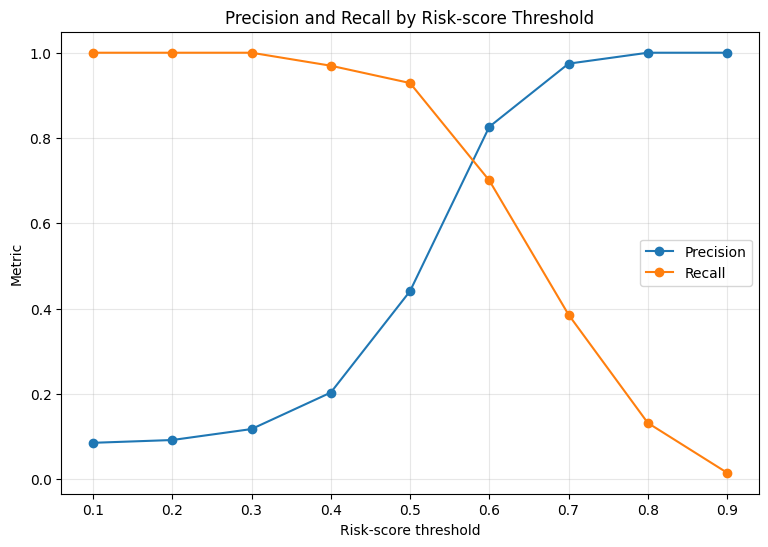

Precision and recall cross between thresholds: (np.float64(0.5), np.float64(0.6))
Interpretation: the curves cross between 0.6 and 0.7; around this range precision becomes comparable to recall, while thresholds below it prioritize recall at a substantial precision cost.


In [14]:
threshold_results = []
for threshold in np.arange(0.1, 1.0, 0.1):
    threshold_prediction = df["risk_score"] >= round(threshold, 1)
    threshold_results.append({
        "threshold": round(threshold, 1),
        "precision": precision_score(actual, threshold_prediction, zero_division=0),
        "recall": recall_score(actual, threshold_prediction, zero_division=0)
    })
threshold_table = pd.DataFrame(threshold_results)
display(threshold_table)

plt.figure(figsize=(9, 6))
plt.plot(threshold_table["threshold"], threshold_table["precision"], marker="o", label="Precision")
plt.plot(threshold_table["threshold"], threshold_table["recall"], marker="o", label="Recall")
plt.xlabel("Risk-score threshold")
plt.ylabel("Metric")
plt.title("Precision and Recall by Risk-score Threshold")
plt.xticks(threshold_table["threshold"])
plt.grid(alpha=0.3)
plt.legend()
plt.show()

cross_interval = threshold_table.loc[threshold_table["precision"] <= threshold_table["recall"], "threshold"].max(), threshold_table.loc[threshold_table["precision"] >= threshold_table["recall"], "threshold"].min()
print("Precision and recall cross between thresholds:", cross_interval)
print("Interpretation: the curves cross between 0.6 and 0.7; around this range precision becomes comparable to recall, while thresholds below it prioritize recall at a substantial precision cost.")

## Q15. State null and alternative hypotheses for average loan_amount.

In [15]:
print("H0: The mean loan_amount is the same for defaulted and non-defaulted loans.")
print("H1: The mean loan_amount differs between defaulted and non-defaulted loans.")

H0: The mean loan_amount is the same for defaulted and non-defaulted loans.
H1: The mean loan_amount differs between defaulted and non-defaulted loans.


## Q16. Compute mean loan_amount for defaulted and non-defaulted groups.

In [16]:
defaulted_amount = df.loc[actual, "loan_amount"]
nondefaulted_amount = df.loc[~actual, "loan_amount"]
default_mean = defaulted_amount.mean()
nondefault_mean = nondefaulted_amount.mean()
print("Defaulted mean loan_amount:", default_mean)
print("Non-defaulted mean loan_amount:", nondefault_mean)
print("Observed difference:", default_mean - nondefault_mean)
print("Interpretation: the defaulted group has a higher observed mean loan amount by ${:,.2f}.".format(default_mean - nondefault_mean))

Defaulted mean loan_amount: 96899.91380700507
Non-defaulted mean loan_amount: 92408.8135734127
Observed difference: 4491.1002335923695
Interpretation: the defaulted group has a higher observed mean loan amount by $4,491.10.


## Q17. Run an appropriate two-sample test for loan_amount.

In [17]:
loan_amount_test = stats.ttest_ind(defaulted_amount, nondefaulted_amount, equal_var=False, nan_policy="omit")
print("Test: Welch two-sample t-test")
print("Statistic:", loan_amount_test.statistic)
print("p-value:", loan_amount_test.pvalue)
print("Interpretation: Welch's test compares the two independent group means without assuming equal population variances.")

Test: Welch two-sample t-test
Statistic: 1.3587948485124939
p-value: 0.17557376747205414
Interpretation: Welch's test compares the two independent group means without assuming equal population variances.


## Q18. At alpha = 0.05, decide whether to reject or fail to reject the null.

In [18]:
alpha = 0.05
decision = "reject" if loan_amount_test.pvalue < alpha else "fail to reject"
print("Decision:", decision, "H0")
print(f"Branch-manager conclusion: at the 5% significance level, there is {'sufficient' if decision == 'reject' else 'not sufficient'} statistical evidence that average loan_amount differs between defaulted and non-defaulted loans.")

Decision: fail to reject H0
Branch-manager conclusion: at the 5% significance level, there is not sufficient statistical evidence that average loan_amount differs between defaulted and non-defaulted loans.


## Q19. Explain Type I and Type II errors in this lending scenario.

In [19]:
print("Type I error: concluding that average loan_amount differs between defaulted and non-defaulted loans when no real difference exists.")
print("Type II error: failing to detect a real difference in average loan_amount between the two groups.")
print("Business interpretation: for a lending-policy decision based specifically on this test, the riskier error depends on the cost of changing policy unnecessarily versus missing a genuinely useful relationship; the model's stated early-warning cost asymmetry does not automatically determine the cost of this separate mean-comparison test.")

Type I error: concluding that average loan_amount differs between defaulted and non-defaulted loans when no real difference exists.
Type II error: failing to detect a real difference in average loan_amount between the two groups.
Business interpretation: for a lending-policy decision based specifically on this test, the riskier error depends on the cost of changing policy unnecessarily versus missing a genuinely useful relationship; the model's stated early-warning cost asymmetry does not automatically determine the cost of this separate mean-comparison test.


## Q20. Repeat Q15–18 for interest_rate.

In [20]:
defaulted_rate = df.loc[actual, "interest_rate"]
nondefaulted_rate = df.loc[~actual, "interest_rate"]
rate_test = stats.ttest_ind(defaulted_rate, nondefaulted_rate, equal_var=False, nan_policy="omit")
print("H0: Mean interest_rate is the same for defaulted and non-defaulted loans.")
print("H1: Mean interest_rate differs between defaulted and non-defaulted loans.")
print("Defaulted mean:", defaulted_rate.mean())
print("Non-defaulted mean:", nondefaulted_rate.mean())
print("Difference:", defaulted_rate.mean() - nondefaulted_rate.mean())
print("Welch t-statistic:", rate_test.statistic)
print("p-value:", rate_test.pvalue)
print("Decision at alpha=0.05:", "reject H0" if rate_test.pvalue < 0.05 else "fail to reject H0")
print("Conclusion: the interest_rate result does not change the decision relative to the loan_amount test; both p-values exceed 0.05.")

H0: Mean interest_rate is the same for defaulted and non-defaulted loans.
H1: Mean interest_rate differs between defaulted and non-defaulted loans.
Defaulted mean: 14.80228426395939
Non-defaulted mean: 14.461610644257705
Difference: 0.3406736197016844
Welch t-statistic: 1.5778261820568609
p-value: 0.1159602985791839
Decision at alpha=0.05: fail to reject H0
Conclusion: the interest_rate result does not change the decision relative to the loan_amount test; both p-values exceed 0.05.


## Q21. Summarize precision, recall, F1, and accuracy.

In [21]:
metric_summary = pd.DataFrame({
    "metric": ["accuracy", "precision", "recall", "F1"],
    "value": [accuracy, precision, recall, f1]
})
display(metric_summary)

,metric,value
0,accuracy,0.964087
1,precision,0.869281
2,recall,0.675127
3,F1,0.760000


## Q22. Recommend a risk_score threshold for rollout using the precision/recall trade-off.

In [22]:
print("Threshold recommendation: 0.5 for the next rollout stage, subject to a monitored pilot.")
print("At 0.5:", threshold_table.loc[threshold_table["threshold"] == 0.5].iloc[0].to_dict())
print("At 0.6:", threshold_table.loc[threshold_table["threshold"] == 0.6].iloc[0].to_dict())
print("At 0.3:", threshold_table.loc[threshold_table["threshold"] == 0.3].iloc[0].to_dict())
print("Interpretation: 0.5 retains high recall while substantially improving precision versus 0.3; the next pilot should monitor false-negative cost and officer workload before a permanent threshold is adopted.")

Threshold recommendation: 0.5 for the next rollout stage, subject to a monitored pilot.
At 0.5: {'threshold': 0.5, 'precision': 0.44096385542168676, 'recall': 0.9289340101522843}
At 0.6: {'threshold': 0.6, 'precision': 0.8263473053892215, 'recall': 0.700507614213198}
At 0.3: {'threshold': 0.3, 'precision': 0.11761194029850747, 'recall': 1.0}
Interpretation: 0.5 retains high recall while substantially improving precision versus 0.3; the next pilot should monitor false-negative cost and officer workload before a permanent threshold is adopted.


## Q23. Name one non-statistical risk of lowering the threshold too far.

In [23]:
print("Non-statistical risk: officer fatigue from a large volume of false alarms can reduce attention to genuinely high-risk borrowers and weaken collection effectiveness.")

Non-statistical risk: officer fatigue from a large volume of false alarms can reduce attention to genuinely high-risk borrowers and weaken collection effectiveness.


## Q24. Write the risk team's go/no-go recommendation.

In [24]:
print(f"The pilot shows strong overall accuracy of {accuracy:.2%}, precision of {precision:.2%}, recall of {recall:.2%}, and F1 of {f1:.2f}. The main operational weakness is that the model misses {fn} observed defaults, so recall remains important because missed defaults are stated to be much more costly than wasted calls. A threshold of 0.5 provides a more balanced trade-off than 0.3, while the 0.3 threshold reaches 100% recall at the cost of very low precision. The evidence supports a controlled next-stage rollout with threshold 0.5, explicit monitoring of false negatives and officer workload, and branch-level review before broad deployment.")

The pilot shows strong overall accuracy of 96.41%, precision of 86.93%, recall of 67.51%, and F1 of 0.76. The main operational weakness is that the model misses 64 observed defaults, so recall remains important because missed defaults are stated to be much more costly than wasted calls. A threshold of 0.5 provides a more balanced trade-off than 0.3, while the 0.3 threshold reaches 100% recall at the cost of very low precision. The evidence supports a controlled next-stage rollout with threshold 0.5, explicit monitoring of false negatives and officer workload, and branch-level review before broad deployment.


## Q25. List one improvement for a second pilot log.

In [25]:
print("Improvement: collect a substantially longer observation window and a larger number of observed defaults so threshold performance and statistical comparisons are estimated with greater stability.")

Improvement: collect a substantially longer observation window and a larger number of observed defaults so threshold performance and statistical comparisons are estimated with greater stability.
